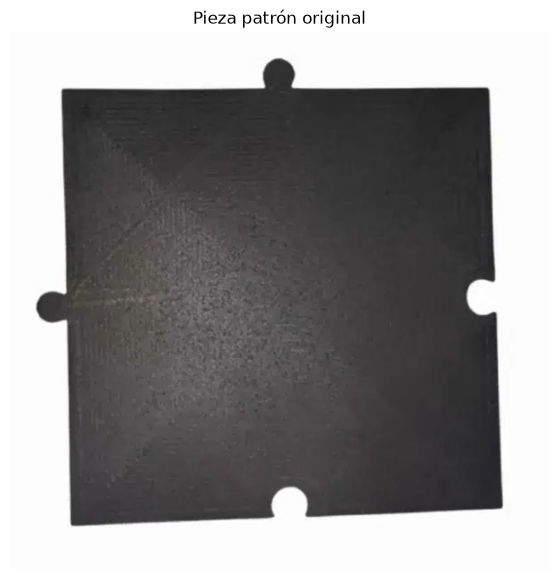

Dimensiones: (600, 600, 3)


In [2]:

# 1. Importar las bibliotecas
import cv2
import matplotlib.pyplot as plt

# 2. Definir la ubicación de la imagen
ruta = r"E:\inspeccion-calidad-caucho\data\patron\pieza_patron.png"

# 3. Cargar la imagen
imagen = cv2.imread(ruta)

# 4. Comprobar que se cargó correctamente
if imagen is None:
    raise FileNotFoundError("No se encontró la imagen. Revisa la ruta.")

# 5. Convertir de BGR a RGB para visualizarla correctamente
imagen_rgb = cv2.cvtColor(imagen, cv2.COLOR_BGR2RGB)

# 6. Mostrar la imagen
plt.figure(figsize=(7, 7))
plt.imshow(imagen_rgb)
plt.title("Pieza patrón original")
plt.axis("off")
plt.show()

# 7. Consultar sus dimensiones en píxeles
print("Dimensiones:", imagen.shape)


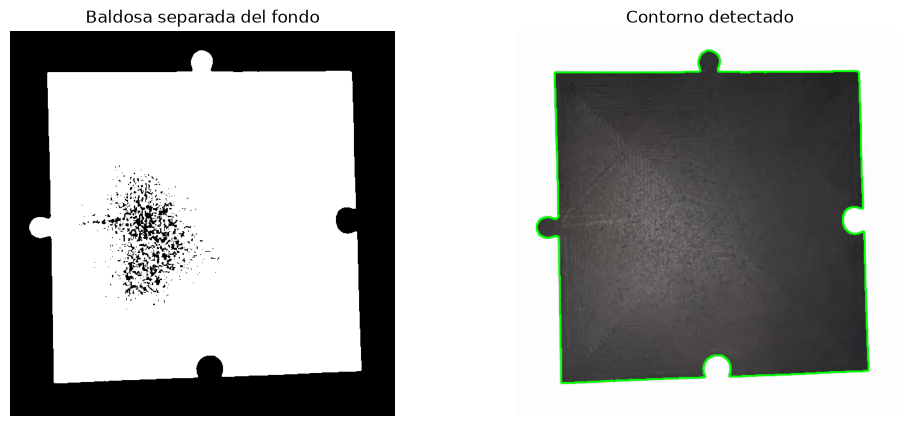

Área de la baldosa: 225594.0 píxeles cuadrados


In [3]:

# 1. Convertir la imagen a escala de grises
gris = cv2.cvtColor(imagen, cv2.COLOR_BGR2GRAY)

# 2. Separar la baldosa del fondo mediante un umbral
_, binaria = cv2.threshold(
    gris, 100, 255, cv2.THRESH_BINARY_INV
)

# 3. Buscar los contornos externos
contornos, jerarquia = cv2.findContours(
    binaria, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
)

# 4. Seleccionar el contorno de mayor área
contorno_principal = max(contornos, key=cv2.contourArea)

# 5. Dibujar el contorno sobre una copia de la imagen original
imagen_contorno = imagen.copy()
cv2.drawContours(
    imagen_contorno, [contorno_principal], -1, (0, 255, 0), 2
)

# 6. Mostrar los resultados
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(binaria, cmap="gray")
plt.title("Baldosa separada del fondo")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(imagen_contorno, cv2.COLOR_BGR2RGB))
plt.title("Contorno detectado")
plt.axis("off")

plt.show()

# 7. Calcular el área del contorno en píxeles
area = cv2.contourArea(contorno_principal)
print("Área de la baldosa:", area, "píxeles cuadrados")


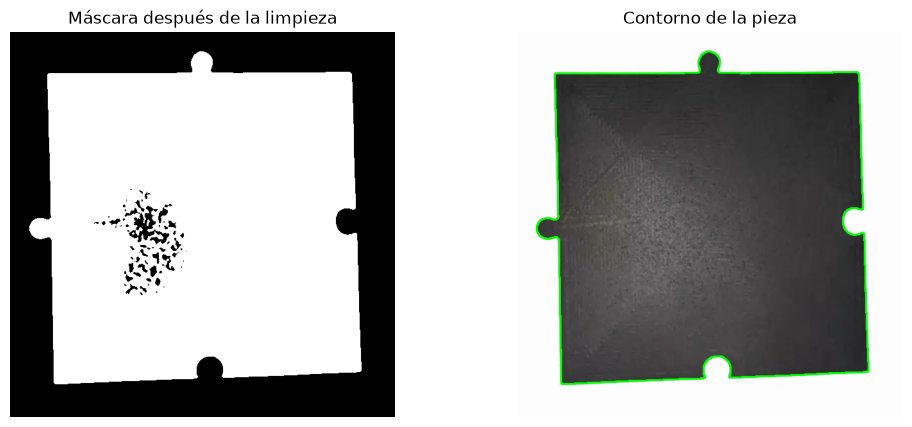

In [4]:

# 1. Aplicar un filtro de mediana para reducir el ruido
gris_limpio = cv2.medianBlur(gris, 5)

# 2. Volver a separar la baldosa del fondo
_, binaria_limpia = cv2.threshold(
    gris_limpio, 100, 255, cv2.THRESH_BINARY_INV
)

# 3. Detectar nuevamente el contorno exterior
contornos_limpios, _ = cv2.findContours(
    binaria_limpia, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
)

# 4. Seleccionar el contorno de mayor área
contorno_principal = max(contornos_limpios, key=cv2.contourArea)

# 5. Dibujar el contorno limpio
imagen_limpia = imagen.copy()
cv2.drawContours(
    imagen_limpia, [contorno_principal], -1, (0, 255, 0), 2
)

# 6. Mostrar los resultados
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(binaria_limpia, cmap="gray")
plt.title("Máscara después de la limpieza")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(imagen_limpia, cv2.COLOR_BGR2RGB))
plt.title("Contorno de la pieza")
plt.axis("off")

plt.show()


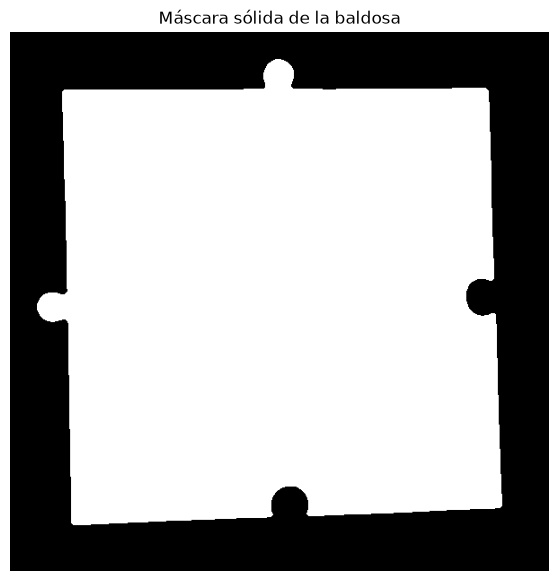

In [5]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. Crear una máscara negra del tamaño de la imagen
mascara_limpia = np.zeros(binaria_limpia.shape, dtype=np.uint8)

# 2. Rellenar completamente el contorno de la baldosa
cv2.drawContours(
    mascara_limpia,
    [contorno_principal],
    -1,
    255,
    thickness=cv2.FILLED
)

# 3. Mostrar la máscara sólida
plt.figure(figsize=(7, 7))
plt.imshow(mascara_limpia, cmap="gray")
plt.title("Máscara sólida de la baldosa")
plt.axis("off")
plt.show()


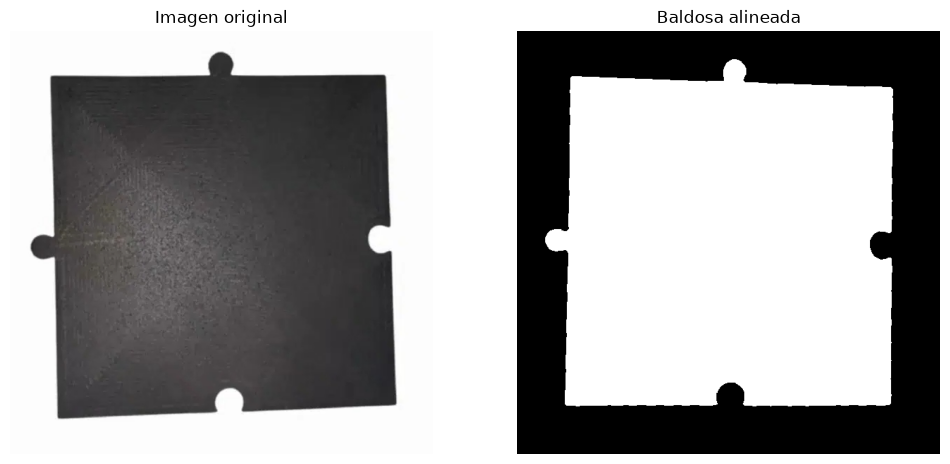

Ángulo de corrección: -2.2 grados


In [6]:

# 1. Calcular el rectángulo mínimo que contiene la baldosa
rectangulo = cv2.minAreaRect(contorno_principal)

# 2. Obtener el ángulo de inclinación
angulo = rectangulo[2]

# 3. Ajustar el ángulo para dejar los bordes horizontales
if angulo < -45:
    angulo = angulo + 90

# 4. Obtener el centro de la imagen
alto, ancho = imagen.shape[:2]
centro = (ancho // 2, alto // 2)

# 5. Crear la matriz de rotación
matriz_rotacion = cv2.getRotationMatrix2D(
    centro, angulo, 1.0
)

# 6. Calcular el tamaño del lienzo para evitar recortes
coseno = abs(matriz_rotacion[0, 0])
seno = abs(matriz_rotacion[0, 1])

nuevo_ancho = int(alto * seno + ancho * coseno)
nuevo_alto = int(alto * coseno + ancho * seno)

# 7. Ajustar la posición de la imagen en el nuevo lienzo
matriz_rotacion[0, 2] += nuevo_ancho / 2 - centro[0]
matriz_rotacion[1, 2] += nuevo_alto / 2 - centro[1]

# 8. Rotar la fotografía original
imagen_alineada = cv2.warpAffine(
    imagen,
    matriz_rotacion,
    (nuevo_ancho, nuevo_alto),
    flags=cv2.INTER_CUBIC,
    borderMode=cv2.BORDER_CONSTANT,
    borderValue=(255, 255, 255)
)

# 9. Rotar también la máscara sólida
mascara_alineada = cv2.warpAffine(
    mascara_limpia,
    matriz_rotacion,
    (nuevo_ancho, nuevo_alto),
    flags=cv2.INTER_NEAREST,
    borderMode=cv2.BORDER_CONSTANT,
    borderValue=0
)

# 10. Mostrar los resultados
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(imagen, cv2.COLOR_BGR2RGB))
plt.title("Imagen original")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(mascara_alineada, cmap="gray")
plt.title("Baldosa alineada")
plt.axis("off")

plt.show()

print("Ángulo de corrección:", round(angulo, 2), "grados")


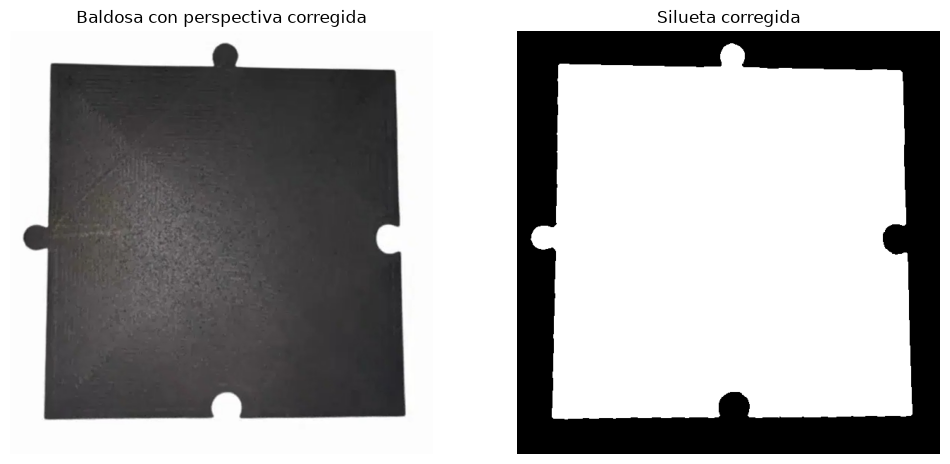

In [7]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. Marcar las cuatro esquinas del cuerpo principal
# Orden: superior izquierda, superior derecha,
# inferior derecha e inferior izquierda
puntos_origen = np.float32([
    [50, 68],
    [536, 57],
    [538, 534],
    [69, 549]
])

# 2. Definir dónde queremos ubicar esas esquinas
# Dejamos un margen de 50 píxeles para conservar los encajes
puntos_destino = np.float32([
    [50, 50],
    [550, 50],
    [550, 550],
    [50, 550]
])

# 3. Calcular la transformación de perspectiva
matriz_perspectiva = cv2.getPerspectiveTransform(
    puntos_origen,
    puntos_destino
)

# 4. Aplicar la transformación a la fotografía
imagen_perspectiva = cv2.warpPerspective(
    imagen,
    matriz_perspectiva,
    (600, 600),
    flags=cv2.INTER_CUBIC,
    borderMode=cv2.BORDER_CONSTANT,
    borderValue=(255, 255, 255)
)

# 5. Aplicar la misma transformación a la máscara
mascara_perspectiva = cv2.warpPerspective(
    mascara_limpia,
    matriz_perspectiva,
    (600, 600),
    flags=cv2.INTER_NEAREST,
    borderMode=cv2.BORDER_CONSTANT,
    borderValue=0
)

# 6. Mostrar la fotografía y la máscara corregidas
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(imagen_perspectiva, cv2.COLOR_BGR2RGB))
plt.title("Baldosa con perspectiva corregida")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(mascara_perspectiva, cmap="gray")
plt.title("Silueta corregida")
plt.axis("off")

plt.show()


In [8]:

# Guardar la fotografía normalizada
cv2.imwrite(
    r"E:\inspeccion-calidad-caucho\data\patron\patron_normalizado.png",
    imagen_perspectiva
)

# Guardar la máscara normalizada
cv2.imwrite(
    r"E:\inspeccion-calidad-caucho\data\patron\mascara_patron.png",
    mascara_perspectiva
)

print("Pieza patrón y máscara guardadas correctamente.")


Pieza patrón y máscara guardadas correctamente.


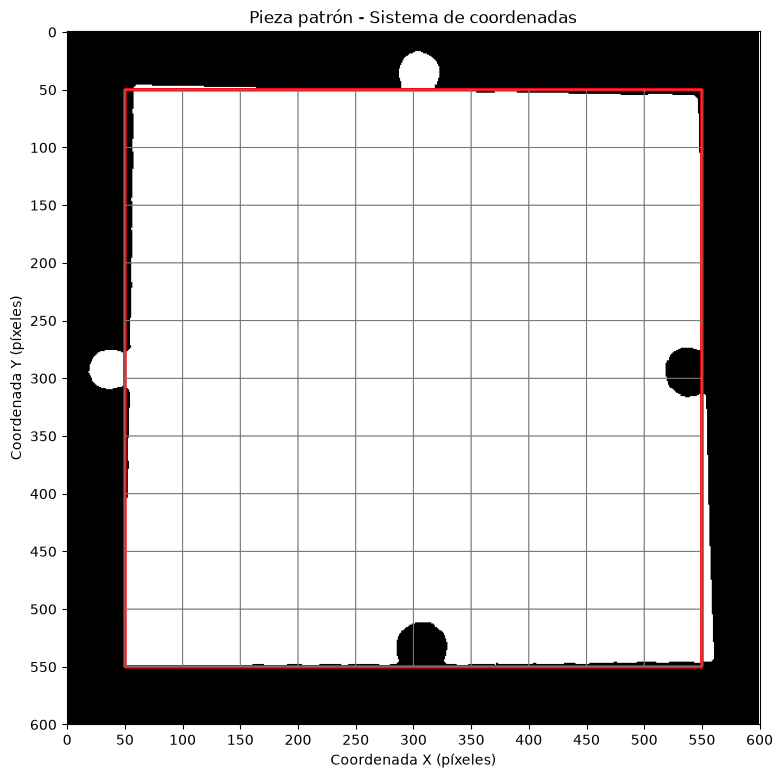

In [9]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. Crear una copia de la máscara normalizada
imagen_referencia = cv2.cvtColor(
    mascara_perspectiva, cv2.COLOR_GRAY2RGB
)

# 2. Dibujar el cuadrado del cuerpo principal
cv2.rectangle(
    imagen_referencia,
    (50, 50),
    (550, 550),
    (255, 0, 0),
    2
)

# 3. Dibujar líneas de referencia cada 50 píxeles
for posicion in range(50, 551, 50):
    cv2.line(
        imagen_referencia,
        (posicion, 50),
        (posicion, 550),
        (120, 120, 120),
        1
    )

    cv2.line(
        imagen_referencia,
        (50, posicion),
        (550, posicion),
        (120, 120, 120),
        1
    )

# 4. Mostrar la pieza con sus referencias
plt.figure(figsize=(9, 9))
plt.imshow(imagen_referencia)
plt.title("Pieza patrón - Sistema de coordenadas")
plt.xlabel("Coordenada X (píxeles)")
plt.ylabel("Coordenada Y (píxeles)")
plt.xticks(np.arange(0, 601, 50))
plt.yticks(np.arange(0, 601, 50))
plt.grid(False)
plt.show()


DIMENSIONES DEL CUERPO PRINCIPAL
Ancho: 500 píxeles
Alto: 500 píxeles


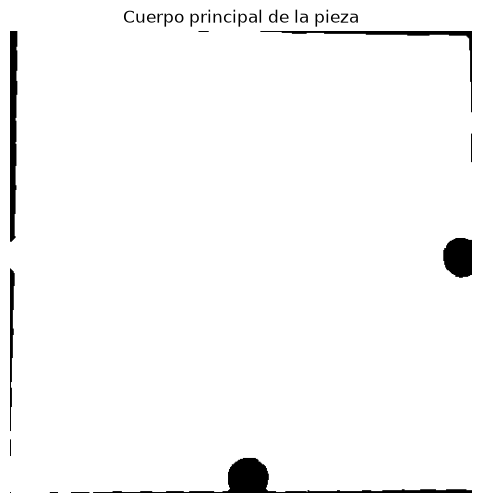

In [10]:
# 1. Recortar el cuerpo principal de la pieza
cuerpo_principal = mascara_perspectiva[50:550, 50:550].copy()

# 2. Encontrar los píxeles blancos
puntos = cv2.findNonZero(cuerpo_principal)

# 3. Obtener el rectángulo que contiene la pieza
x, y, ancho, alto = cv2.boundingRect(puntos)

# 4. Mostrar las dimensiones
print("DIMENSIONES DEL CUERPO PRINCIPAL")
print(f"Ancho: {ancho} píxeles")
print(f"Alto: {alto} píxeles")

# 5. Visualizar el recorte
plt.figure(figsize=(6, 6))
plt.imshow(cuerpo_principal, cmap="gray")
plt.title("Cuerpo principal de la pieza")
plt.axis("off")
plt.show()

In [11]:
# Dimensiones físicas nominales de la pieza
ancho_real_mm = 500
alto_real_mm = 500

# Dimensiones en píxeles
ancho_px = 500
alto_px = 500

# Calcular la escala
escala_x = ancho_real_mm / ancho_px
escala_y = alto_real_mm / alto_px

print(f"Escala horizontal: {escala_x} mm/píxel")
print(f"Escala vertical: {escala_y} mm/píxel")

Escala horizontal: 1.0 mm/píxel
Escala vertical: 1.0 mm/píxel


In [12]:
# Convertir las dimensiones de píxeles a milímetros
ancho_mm = ancho_px * escala_x
alto_mm = alto_px * escala_y

print("DIMENSIONES ESTIMADAS DE LA PIEZA")
print(f"Ancho: {ancho_mm:.2f} mm")
print(f"Alto: {alto_mm:.2f} mm")

DIMENSIONES ESTIMADAS DE LA PIEZA
Ancho: 500.00 mm
Alto: 500.00 mm


In [20]:
import os

# Ruta de la carpeta de imágenes
carpeta = r"E:\inspeccion-calidad-caucho\data\patron"

# Mostrar todos los archivos y sus extensiones
for archivo in os.listdir(carpeta):
    ruta_completa = os.path.join(carpeta, archivo)
    print(archivo, "| Existe:", os.path.isfile(ruta_completa))

mascara_patron.png | Existe: True
patron_normalizado.png | Existe: True
pieza_patron.png | Existe: True


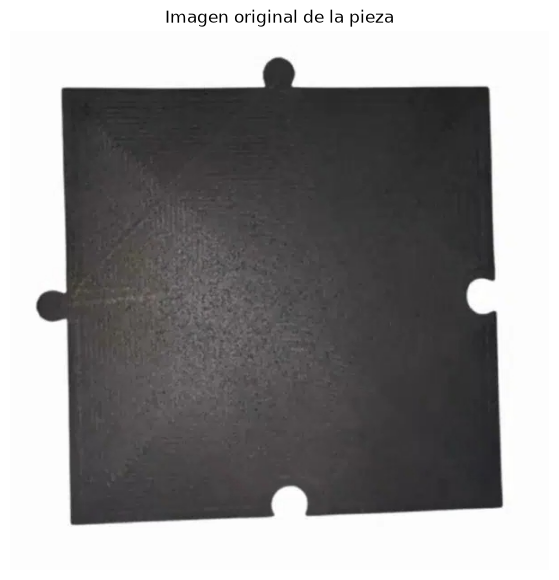

In [21]:
# 1. Cargar la imagen original
ruta_imagen = r"E:\inspeccion-calidad-caucho\data\patron\pieza_patron.png"

imagen_original = cv2.imread(ruta_imagen)

# 2. Convertir de BGR a RGB
imagen_rgb = cv2.cvtColor(imagen_original, cv2.COLOR_BGR2RGB)

# 3. Mostrar la imagen
plt.figure(figsize=(7, 7))
plt.imshow(imagen_rgb)
plt.title("Imagen original de la pieza")
plt.axis("off")
plt.show()

In [22]:
# 1. Convertir la imagen de BGR a HSV
imagen_hsv = cv2.cvtColor(imagen_original, cv2.COLOR_BGR2HSV)

# 2. Separar los canales
canal_h, canal_s, canal_v = cv2.split(imagen_hsv)

# 3. Calcular el brillo promedio de la imagen
brillo_promedio = np.mean(canal_v)

# 4. Mostrar el resultado
print("ANÁLISIS DEL COLOR")
print(f"Brillo promedio: {brillo_promedio:.2f}")

ANÁLISIS DEL COLOR
Brillo promedio: 134.84


In [23]:
# 1. Redimensionar la máscara al tamaño de la imagen original
mascara_color = cv2.resize(
    mascara_perspectiva,
    (imagen_original.shape[1], imagen_original.shape[0])
)

# 2. Seleccionar únicamente los píxeles de la pieza
pixeles_pieza = canal_v[mascara_color > 0]

# 3. Calcular el brillo promedio de la superficie
brillo_pieza = np.mean(pixeles_pieza)

# 4. Mostrar el resultado
print("INSPECCIÓN DEL COLOR DE LA PIEZA")
print(f"Brillo promedio de la superficie: {brillo_pieza:.2f}")

INSPECCIÓN DEL COLOR DE LA PIEZA
Brillo promedio de la superficie: 81.61


In [24]:
# Calcular la saturación promedio de la pieza
saturacion_pieza = np.mean(
    imagen_hsv[:, :, 1][mascara_color > 0]
)

print("RESULTADOS DEL COLOR")
print(f"Brillo promedio: {brillo_pieza:.2f}")
print(f"Saturación promedio: {saturacion_pieza:.2f}")

RESULTADOS DEL COLOR
Brillo promedio: 81.61
Saturación promedio: 8.01


In [25]:
# Definir los límites de inspección
umbral_brillo = 100
umbral_saturacion = 30

# Evaluar el color de la pieza
if brillo_pieza <= umbral_brillo and saturacion_pieza <= umbral_saturacion:
    resultado_color = "NEGRO - APROBADO"
else:
    resultado_color = "COLOR NO CONFORME - RECHAZADO"

# Mostrar resultado
print("RESULTADO DE INSPECCIÓN")
print(resultado_color)

RESULTADO DE INSPECCIÓN
NEGRO - APROBADO


## 3. Inspección de la geometría general

### Objetivo
Verificar que la forma general de las láminas de caucho corresponda con la geometría de la pieza patrón, identificando posibles deformaciones o alteraciones en su contorno.

### Metodología
Se utilizarán técnicas de procesamiento de imágenes mediante OpenCV para extraer el contorno exterior de la pieza patrón y compararlo posteriormente con los contornos de las piezas inspeccionadas.

Para realizar la comparación se utilizará la función `cv2.matchShapes()`, basada en momentos de forma, que permite evaluar la similitud entre dos contornos.

### Criterio de aceptación
La pieza será considerada geométricamente conforme cuando su contorno presente una similitud suficiente con respecto al patrón de referencia.

### Herramientas
- Python.
- OpenCV.
- NumPy.
- Matplotlib.

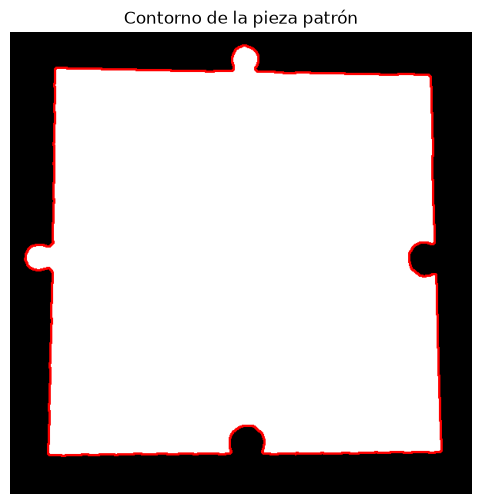

In [26]:
# 1. Encontrar el contorno de la pieza patrón
contornos_patron, _ = cv2.findContours(
    mascara_perspectiva.copy(),
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE
)

# 2. Seleccionar el contorno más grande
contorno_patron = max(contornos_patron, key=cv2.contourArea)

# 3. Mostrar el contorno encontrado
imagen_contorno = cv2.cvtColor(
    mascara_perspectiva.copy(),
    cv2.COLOR_GRAY2RGB
)

cv2.drawContours(
    imagen_contorno,
    [contorno_patron],
    -1,
    (255, 0, 0),
    2
)

plt.figure(figsize=(6, 6))
plt.imshow(imagen_contorno)
plt.title("Contorno de la pieza patrón")
plt.axis("off")
plt.show()

In [27]:
# Calcular el área del contorno patrón
area_patron = cv2.contourArea(contorno_patron)

# Calcular el perímetro del contorno patrón
perimetro_patron = cv2.arcLength(contorno_patron, True)

print("CARACTERÍSTICAS DE LA PIEZA PATRÓN")
print(f"Área: {area_patron:.2f} píxeles cuadrados")
print(f"Perímetro: {perimetro_patron:.2f} píxeles")

CARACTERÍSTICAS DE LA PIEZA PATRÓN
Área: 246436.50 píxeles cuadrados
Perímetro: 2270.20 píxeles


In [28]:
# 1. Comparar el contorno patrón consigo mismo
similitud = cv2.matchShapes(
    contorno_patron,
    contorno_patron,
    cv2.CONTOURS_MATCH_I1,
    0.0
)

# 2. Mostrar el resultado
print("COMPARACIÓN GEOMÉTRICA")
print(f"Índice de diferencia: {similitud:.6f}")

if similitud < 0.01:
    print("GEOMETRÍA CONFORME")
else:
    print("GEOMETRÍA NO CONFORME")

COMPARACIÓN GEOMÉTRICA
Índice de diferencia: 0.000000
GEOMETRÍA CONFORME


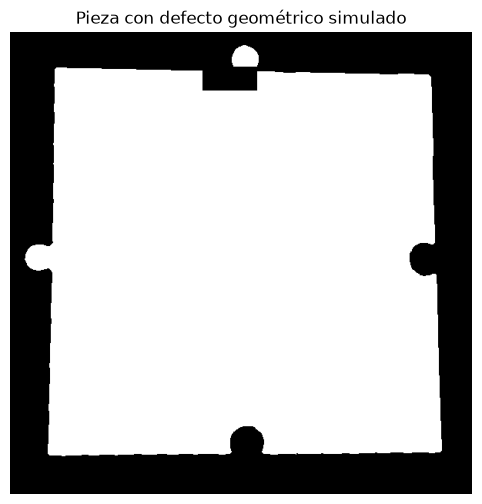

In [29]:
# 1. Crear una copia de la máscara original
mascara_defectuosa = mascara_perspectiva.copy()

# 2. Simular un daño en el borde superior
cv2.rectangle(
    mascara_defectuosa,
    (250, 45),
    (320, 75),
    0,
    -1
)

# 3. Mostrar la pieza modificada
plt.figure(figsize=(6, 6))
plt.imshow(mascara_defectuosa, cmap="gray")
plt.title("Pieza con defecto geométrico simulado")
plt.axis("off")
plt.show()

In [30]:
# 1. Extraer los contornos de la pieza defectuosa
contornos_defectuosos, _ = cv2.findContours(
    mascara_defectuosa.copy(),
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE
)

# 2. Seleccionar el contorno más grande
contorno_defectuoso = max(
    contornos_defectuosos,
    key=cv2.contourArea
)

# 3. Comparar con el contorno patrón
diferencia = cv2.matchShapes(
    contorno_patron,
    contorno_defectuoso,
    cv2.CONTOURS_MATCH_I1,
    0.0
)

# 4. Mostrar el resultado
print("INSPECCIÓN GEOMÉTRICA")
print(f"Índice de diferencia: {diferencia:.6f}")

INSPECCIÓN GEOMÉTRICA
Índice de diferencia: 0.004209


In [33]:
# Clasificar la pieza según su geometría
if diferencia <= umbral_geometrico:
    resultado_geometria = "GEOMETRÍA CONFORME"
    decision = "PIEZA ACEPTADA"
else:
    resultado_geometria = "GEOMETRÍA NO CONFORME"
    decision = "PIEZA RECHAZADA"

# Mostrar resultados
print("RESULTADO DE INSPECCIÓN")
print("------------------------------")
print(resultado_geometria)
print("------------------------------")
print(decision)

RESULTADO DE INSPECCIÓN
------------------------------
GEOMETRÍA NO CONFORME
------------------------------
PIEZA RECHAZADA


## 4. Detección de defectos superficiales

### Objetivo
Identificar alteraciones visibles en la superficie de las láminas de caucho que puedan afectar su calidad.

### Metodología
Se utilizará el canal de brillo (V) del espacio de color HSV para analizar la superficie de la pieza. Mediante un umbral de intensidad se identificarán zonas anormalmente claras que puedan representar manchas o daños superficiales.

Para comprobar el funcionamiento del procedimiento se generará una imagen con un defecto simulado y se comparará con la pieza de referencia.

### Criterio de aceptación
La pieza será evaluada según la presencia de alteraciones superficiales detectadas dentro de su área.

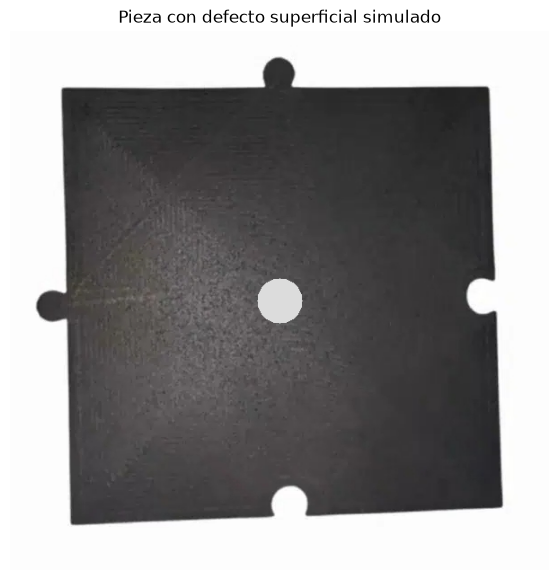

In [34]:
# 1. Crear una copia de la imagen original
imagen_defectuosa = imagen_original.copy()

# 2. Simular una mancha clara sobre la superficie
cv2.circle(
    imagen_defectuosa,
    (300, 300),
    25,
    (220, 220, 220),
    -1
)

# 3. Mostrar la imagen modificada
imagen_defectuosa_rgb = cv2.cvtColor(
    imagen_defectuosa,
    cv2.COLOR_BGR2RGB
)

plt.figure(figsize=(7, 7))
plt.imshow(imagen_defectuosa_rgb)
plt.title("Pieza con defecto superficial simulado")
plt.axis("off")
plt.show()

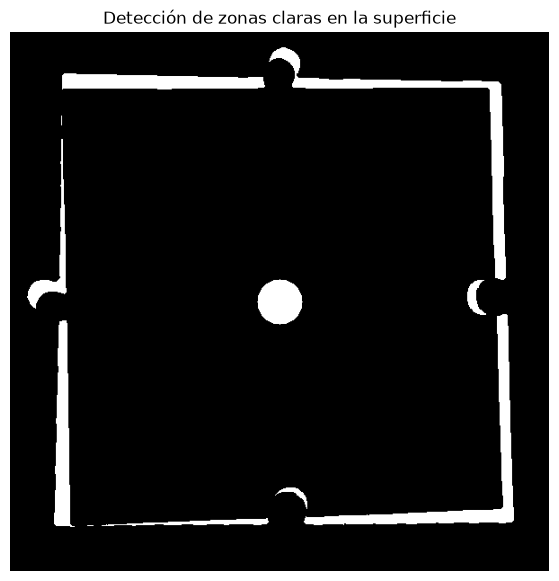

In [35]:
# 1. Convertir la imagen defectuosa a HSV
imagen_hsv_defectuosa = cv2.cvtColor(
    imagen_defectuosa,
    cv2.COLOR_BGR2HSV
)

# 2. Extraer el canal de brillo
canal_brillo = imagen_hsv_defectuosa[:, :, 2]

# 3. Identificar zonas claras dentro de la pieza
mascara_defectos = cv2.inRange(
    canal_brillo,
    180,
    255
)

# 4. Excluir el fondo utilizando la máscara de la pieza
mascara_defectos = cv2.bitwise_and(
    mascara_defectos,
    mascara_color
)

# 5. Mostrar las zonas detectadas
plt.figure(figsize=(7, 7))
plt.imshow(mascara_defectos, cmap="gray")
plt.title("Detección de zonas claras en la superficie")
plt.axis("off")
plt.show()

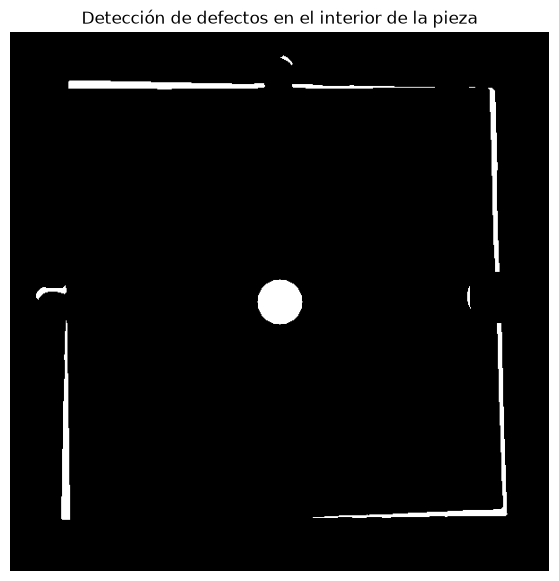

In [36]:
# 1. Crear un elemento estructurante
kernel = np.ones((15, 15), np.uint8)

# 2. Reducir ligeramente la máscara de la pieza
mascara_interior = cv2.erode(
    mascara_color,
    kernel,
    iterations=1
)

# 3. Aplicar nuevamente la detección de defectos
mascara_defectos = cv2.bitwise_and(
    mascara_defectos,
    mascara_interior
)

# 4. Mostrar el resultado
plt.figure(figsize=(7, 7))
plt.imshow(mascara_defectos, cmap="gray")
plt.title("Detección de defectos en el interior de la pieza")
plt.axis("off")
plt.show()

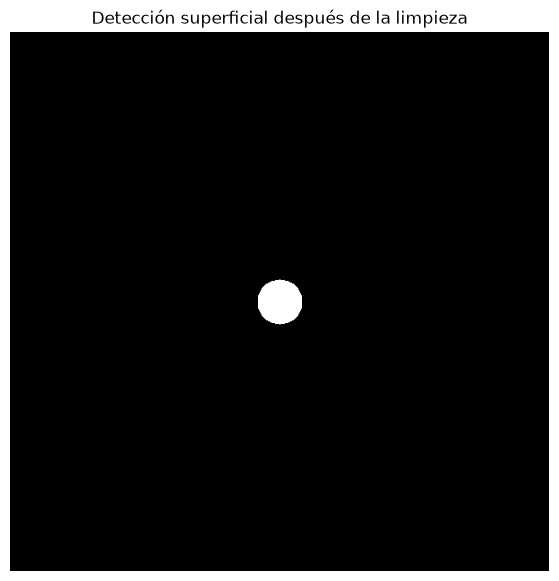

In [37]:
# 1. Crear un elemento estructurante elíptico
kernel_limpieza = cv2.getStructuringElement(
    cv2.MORPH_ELLIPSE,
    (15, 15)
)

# 2. Aplicar apertura morfológica
mascara_limpia = cv2.morphologyEx(
    mascara_defectos,
    cv2.MORPH_OPEN,
    kernel_limpieza
)

# 3. Mostrar el resultado
plt.figure(figsize=(7, 7))
plt.imshow(mascara_limpia, cmap="gray")
plt.title("Detección superficial después de la limpieza")
plt.axis("off")
plt.show()

In [38]:
# 1. Calcular el área de los píxeles blancos detectados
area_defecto = cv2.countNonZero(mascara_limpia)

# 2. Definir el límite permitido
umbral_area = 100

# 3. Clasificar la superficie
if area_defecto > umbral_area:
    resultado_superficie = "SUPERFICIE NO CONFORME"
    decision_superficie = "PIEZA RECHAZADA"
else:
    resultado_superficie = "SUPERFICIE CONFORME"
    decision_superficie = "PIEZA ACEPTADA"

# 4. Mostrar resultados
print("INSPECCIÓN DE SUPERFICIE")
print(f"Área del defecto: {area_defecto} píxeles cuadrados")
print(resultado_superficie)
print(decision_superficie)

INSPECCIÓN DE SUPERFICIE
Área del defecto: 1951 píxeles cuadrados
SUPERFICIE NO CONFORME
PIEZA RECHAZADA


## 5. Clasificación final de calidad

### Objetivo
Integrar los resultados de las inspecciones dimensional, de color, geométrica y superficial para generar una decisión automática sobre la calidad de cada lámina de caucho.

### Metodología
Se combinarán los resultados obtenidos en los módulos anteriores mediante condiciones lógicas. La pieza será aceptada únicamente cuando cumpla todos los criterios establecidos.

Si alguna de las inspecciones identifica una condición no conforme, el sistema clasificará la pieza como rechazada.

### Criterio de decisión
- Pieza aceptada: cumple todas las condiciones de calidad.
- Pieza rechazada: incumple al menos una condición.

In [39]:
# 1. Evaluar las dimensiones
dimensiones_ok = (
    498 <= ancho_mm <= 502 and
    498 <= alto_mm <= 502
)

# 2. Evaluar el color
color_ok = (
    brillo_pieza <= 100 and
    saturacion_pieza <= 30
)

# 3. Evaluar la geometría
geometria_ok = diferencia <= umbral_geometrico

# 4. Evaluar la superficie
superficie_ok = area_defecto <= umbral_area

# 5. Integrar todas las inspecciones
pieza_aceptada = (
    dimensiones_ok and
    color_ok and
    geometria_ok and
    superficie_ok
)

# 6. Mostrar los resultados
print("INFORME FINAL DE INSPECCIÓN")
print("--------------------------------")

print("Dimensiones:", "CONFORME" if dimensiones_ok else "NO CONFORME")
print("Color:", "CONFORME" if color_ok else "NO CONFORME")
print("Geometría:", "CONFORME" if geometria_ok else "NO CONFORME")
print("Superficie:", "CONFORME" if superficie_ok else "NO CONFORME")

print("--------------------------------")

if pieza_aceptada:
    print("DECISIÓN FINAL: PIEZA ACEPTADA")
else:
    print("DECISIÓN FINAL: PIEZA RECHAZADA")

INFORME FINAL DE INSPECCIÓN
--------------------------------
Dimensiones: CONFORME
Color: CONFORME
Geometría: NO CONFORME
Superficie: NO CONFORME
--------------------------------
DECISIÓN FINAL: PIEZA RECHAZADA


## 6. Simulación de la acción robótica

### Objetivo
Representar la respuesta automática de una línea de producción según la clasificación obtenida mediante visión artificial.

### Metodología
La decisión final del sistema de inspección se utilizará como señal de control para activar un desviador lateral simulado.

- Si la pieza es aceptada, continúa por la banda transportadora.
- Si la pieza es rechazada, se activa el desviador lateral y se dirige al contenedor de productos no conformes.

### Resultado esperado
Demostrar la integración entre el sistema de percepción, la clasificación de calidad y la acción automatizada de separación de productos.

In [40]:
# Simular la acción del sistema de separación

if pieza_aceptada:
    accion_robotica = "DESVIADOR INACTIVO"
    destino = "CONTINÚA POR LA BANDA TRANSPORTADORA"
else:
    accion_robotica = "DESVIADOR ACTIVADO"
    destino = "CONTENEDOR DE PIEZAS RECHAZADAS"

print("SISTEMA DE SEPARACIÓN AUTOMÁTICA")
print("--------------------------------")
print("Clasificación:", "ACEPTADA" if pieza_aceptada else "RECHAZADA")
print("Acción:", accion_robotica)
print("Destino:", destino)

SISTEMA DE SEPARACIÓN AUTOMÁTICA
--------------------------------
Clasificación: RECHAZADA
Acción: DESVIADOR ACTIVADO
Destino: CONTENEDOR DE PIEZAS RECHAZADAS


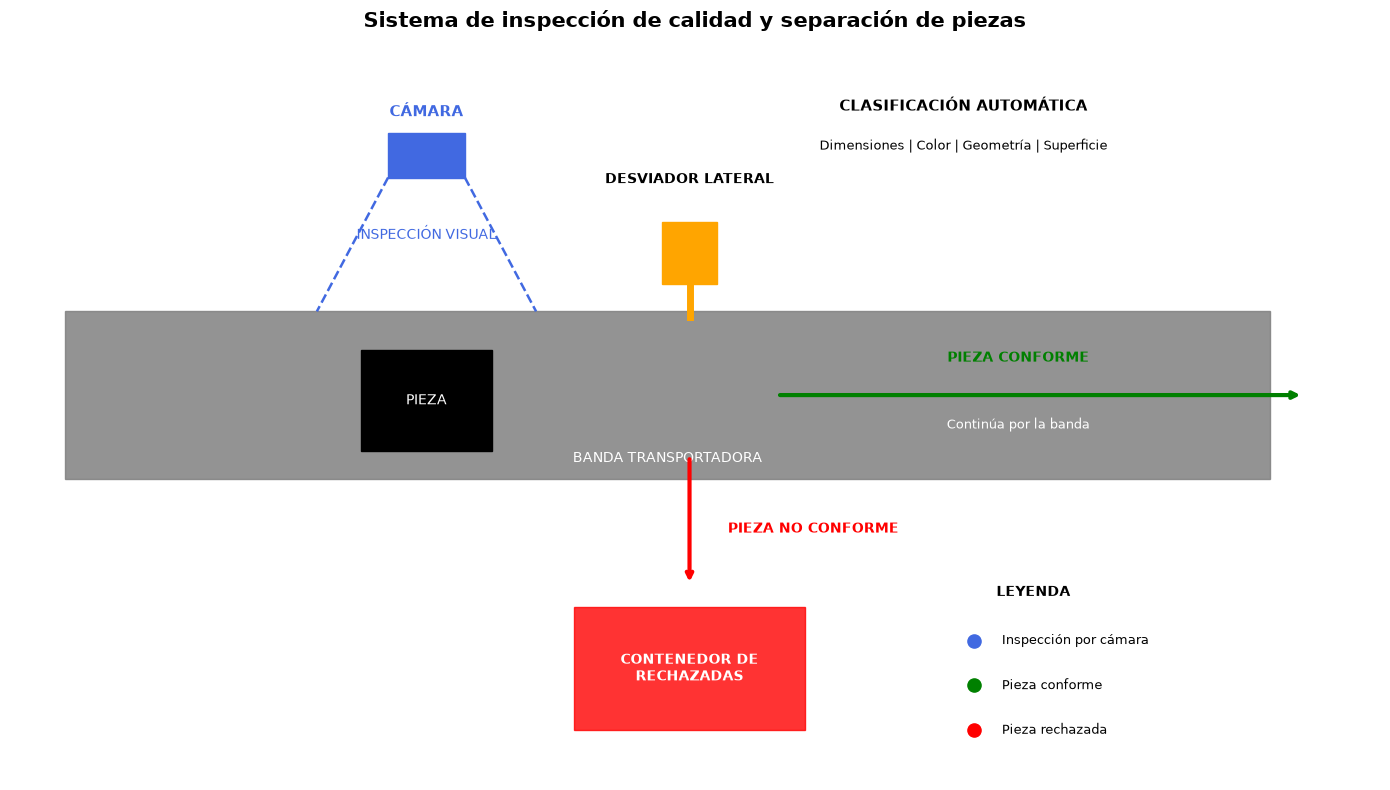

In [43]:

# SISTEMA DE INSPECCIÓN Y SEPARACIÓN DE PIEZAS

fig, ax = plt.subplots(figsize=(14, 8))

# 1. Banda transportadora
banda = plt.Rectangle((0.5, 2.7), 11, 1.5,
                      color="gray", alpha=0.85)
ax.add_patch(banda)

ax.text(6, 2.85, "BANDA TRANSPORTADORA",
        color="white", ha="center", fontsize=10)

# 2. Pieza de caucho
pieza = plt.Rectangle((3.2, 2.95), 1.2, 0.9,
                      color="black")
ax.add_patch(pieza)

ax.text(3.8, 3.4, "PIEZA", color="white",
        ha="center", va="center", fontsize=10)

# 3. Cámara de visión artificial
camara = plt.Rectangle((3.45, 5.4), 0.7, 0.4,
                       color="royalblue")
ax.add_patch(camara)

ax.text(3.8, 5.95, "CÁMARA",
        color="royalblue", ha="center",
        fontsize=11, weight="bold")

# Campo visual
ax.plot([3.45, 2.8], [5.4, 4.2],
        "--", color="royalblue", lw=1.8)
ax.plot([4.15, 4.8], [5.4, 4.2],
        "--", color="royalblue", lw=1.8)

ax.text(3.8, 4.85, "INSPECCIÓN VISUAL",
        color="royalblue", ha="center", fontsize=10)

# 4. Clasificación automática
ax.text(8.7, 6.0, "CLASIFICACIÓN AUTOMÁTICA",
        ha="center", fontsize=11, weight="bold")

ax.text(8.7, 5.65,
        "Dimensiones | Color | Geometría | Superficie",
        ha="center", fontsize=9)

# 5. Desviador lateral y actuador
ax.text(6.2, 5.35, "DESVIADOR LATERAL",
        ha="center", fontsize=10, weight="bold")

actuador = plt.Rectangle((5.95, 4.45), 0.5, 0.55,
                         color="orange")
ax.add_patch(actuador)

# Varilla del desviador
ax.plot([6.2, 6.2], [4.45, 4.15],
        color="orange", lw=5)

# 6. Flujo de piezas conformes
ax.annotate("",
            xy=(11.8, 3.45), xytext=(7.0, 3.45),
            arrowprops=dict(arrowstyle="->",
                            color="green", lw=3))

ax.text(9.2, 3.75, "PIEZA CONFORME",
        color="green", ha="center",
        fontsize=10, weight="bold")

ax.text(9.2, 3.15, "Continúa por la banda",
        color="white", ha="center", fontsize=9)

# 7. Ruta de rechazo lateral
ax.annotate("",
            xy=(6.2, 1.75), xytext=(6.2, 2.9),
            arrowprops=dict(arrowstyle="->",
                            color="red", lw=3))

ax.text(6.55, 2.25, "PIEZA NO CONFORME",
        color="red", fontsize=10, weight="bold",
        va="center")

# 8. Contenedor de rechazo
contenedor = plt.Rectangle((5.15, 0.45), 2.1, 1.1,
                           color="red", alpha=0.8)
ax.add_patch(contenedor)

ax.text(6.2, 1.0, "CONTENEDOR DE\nRECHAZADAS",
        color="white", ha="center", va="center",
        fontsize=10, weight="bold")

# 9. Leyenda
ax.text(9.0, 1.65, "LEYENDA",
        fontsize=10, weight="bold")

ax.scatter([8.8], [1.25], color="royalblue", s=90)
ax.text(9.05, 1.25, "Inspección por cámara",
        va="center", fontsize=9)

ax.scatter([8.8], [0.85], color="green", s=90)
ax.text(9.05, 0.85, "Pieza conforme",
        va="center", fontsize=9)

ax.scatter([8.8], [0.45], color="red", s=90)
ax.text(9.05, 0.45, "Pieza rechazada",
        va="center", fontsize=9)

# 10. Título y presentación
ax.set_title(
    "Sistema de inspección de calidad y separación de piezas",
    fontsize=15, weight="bold", pad=20
)

ax.set_xlim(0, 12.5)
ax.set_ylim(0, 6.5)
ax.axis("off")

plt.tight_layout()
plt.show()


In [45]:
fig.savefig(
    r"E:\inspeccion-calidad-caucho\resultados\simulacion\diseno_linea_inspeccion.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## 7. Construcción del conjunto de datos (Dataset)

### 7.1. Carga de la imagen patrón

**Objetivo:** utilizar la imagen original de la lámina de caucho como referencia para generar imágenes sintéticas conformes y defectuosas.

Se carga la fotografía mediante OpenCV y se comprueba que la imagen se haya leído correctamente, verificando sus dimensiones y representación visual.

La imagen patrón conservará la geometría original del producto y servirá como base para las variaciones del conjunto de datos.


In [46]:

from pathlib import Path

# Carpeta principal del conjunto de datos
ruta_dataset = Path(r"E:\inspeccion-calidad-caucho\data")

# Crear carpetas para las imágenes
(ruta_dataset / "correctas").mkdir(parents=True, exist_ok=True)
(ruta_dataset / "defectuosas").mkdir(parents=True, exist_ok=True)

print("Carpetas del dataset preparadas correctamente.")
print("Imágenes conformes:", ruta_dataset / "correctas")
print("Imágenes defectuosas:", ruta_dataset / "defectuosas")


Carpetas del dataset preparadas correctamente.
Imágenes conformes: E:\inspeccion-calidad-caucho\data\correctas
Imágenes defectuosas: E:\inspeccion-calidad-caucho\data\defectuosas


Imagen patrón cargada correctamente.
Dimensiones: (600, 600, 3)


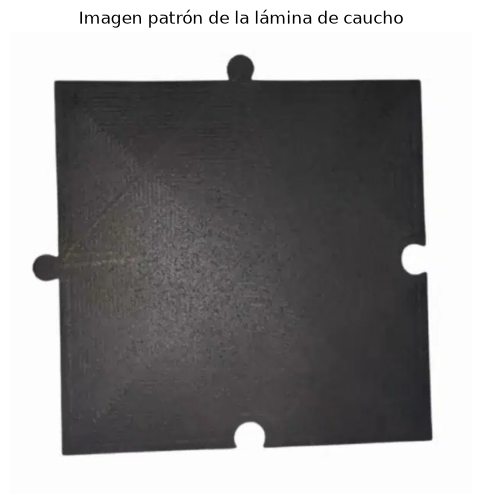

In [47]:

# Ruta de nuestra lámina original
ruta_patron = r"E:\inspeccion-calidad-caucho\data\patron\pieza_patron.png"

# Cargar la imagen
imagen_patron = cv2.imread(ruta_patron)

# Comprobar que se cargó correctamente
if imagen_patron is None:
    print("ERROR: No se pudo cargar la imagen patrón.")
else:
    print("Imagen patrón cargada correctamente.")
    print("Dimensiones:", imagen_patron.shape)

    # Mostrar la imagen
    imagen_rgb = cv2.cvtColor(imagen_patron, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(6, 6))
    plt.imshow(imagen_rgb)
    plt.title("Imagen patrón de la lámina de caucho")
    plt.axis("off")
    plt.show()



### 7.2. Generación de imágenes conformes

Se generan imágenes sintéticas a partir de la fotografía patrón, aplicando pequeñas variaciones de iluminación, brillo, contraste y posición.

Estas modificaciones permiten simular diferentes condiciones de captura sin cambiar las dimensiones ni la geometría original de la lámina.

Las imágenes se etiquetan como conformes y se almacenan en la carpeta `data/correctas`.


In [ ]:

import random

# Crear una carpeta para guardar las imágenes
carpeta_correctas = ruta_dataset / "correctas"

# Generar cinco variaciones
for i in range(5):

    # Crear una copia de la imagen original
    imagen = imagen_patron.copy()

    # Variar ligeramente el brillo y el contraste
    brillo = random.randint(-10, 10)
    contraste = random.uniform(0.95, 1.05)

    imagen = cv2.convertScaleAbs(
        imagen,
        alpha=contraste,
        beta=brillo
    )

    # Guardar la imagen generada
    nombre = f"correcta_{i+1:03d}.png"
    ruta_salida = carpeta_correctas / nombre

    cv2.imwrite(str(ruta_salida), imagen)

    print("Imagen guardada:", nombre)

print("\nGeneración de prueba finalizada.")
